<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Hysteresis_Loop_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

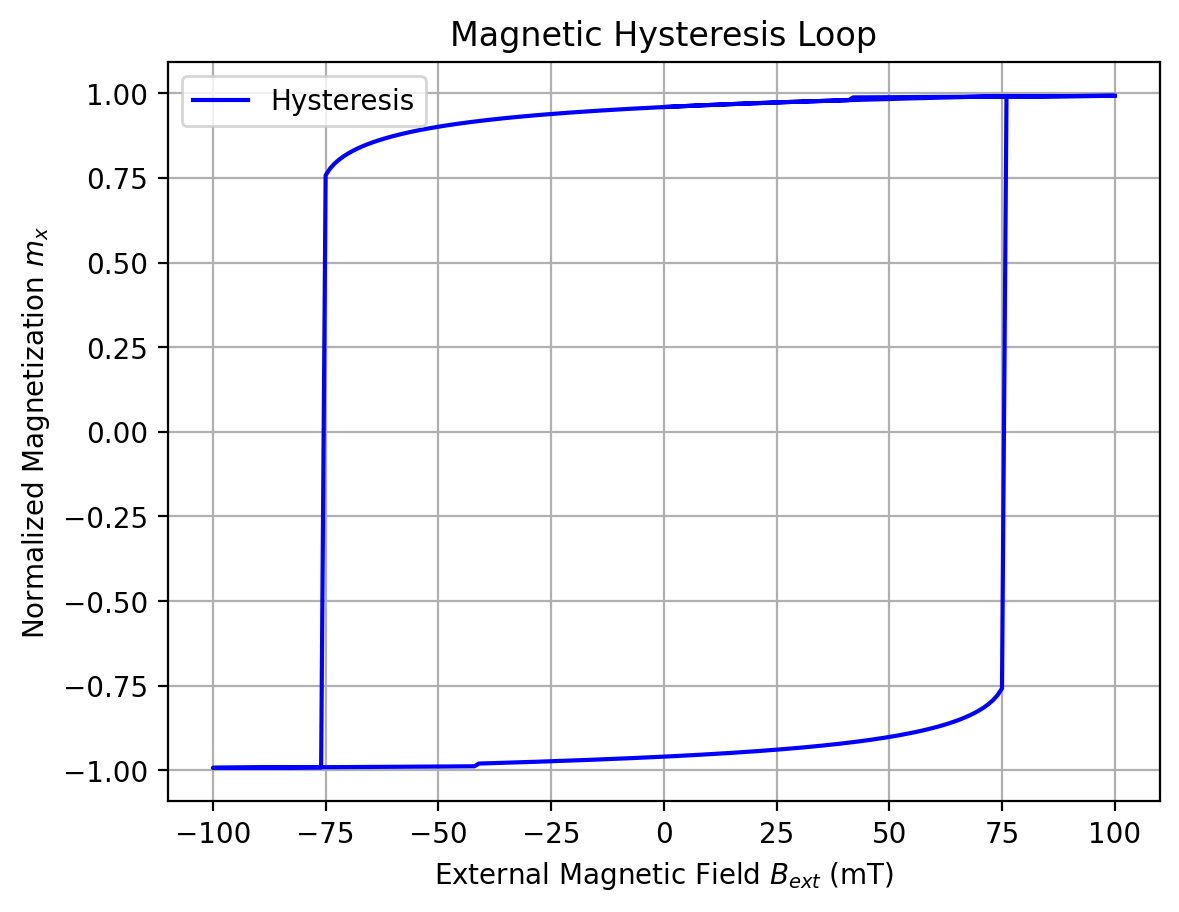

In [5]:
"""This script calculates the magnetic hysteresis loop using mumaxplus.
"""

import matplotlib.pyplot as plt
import numpy as np

from mumaxplus import Ferromagnet
from mumaxplus import Grid
from mumaxplus import World

plt.rcParams['figure.dpi'] = 200

# DOMAIN SPECIFICATIONS
world = World(cellsize=(4e-9, 4e-9, 30e-9))
magnet = Ferromagnet(world, Grid((128, 32, 1)))

# FERROMAGNET INITIALIZATION
magnet.msat = 800e3
magnet.aex = 13e-12
magnet.alpha = 0.5

magnet.magnetization = np.random.uniform(-1.0, 1.0, (3, 1, 32, 128))
magnet.relax()

# HYSTERESIS FIELD SWEEP
b_max = 100e-3
b_step = 1e-3

b_array = np.concatenate((
    np.arange(0.0, b_max + b_step * 0.5, b_step),
    np.arange(b_max, -b_max - b_step * 0.5, -b_step),
    np.arange(-b_max, b_max + b_step * 0.5, b_step)
))

bias_list = []
mx_list = []

for b_ext in b_array:
    world.bias_magnetic_field = (b_ext, 0.0, 0.0)
    magnet.minimize()

    bias_list.append(b_ext)
    mx_list.append(magnet.magnetization.average()[0])

# VISUALIZATION RENDERING
plt.plot(
    np.array(bias_list) * 1e3,
    mx_list,
    color="#0000FF",
    linewidth=1.5,
    label="Hysteresis"
)
plt.xlabel("External Magnetic Field $B_{ext}$ (mT)")
plt.ylabel("Normalized Magnetization $m_x$")
plt.title("Magnetic Hysteresis Loop")
plt.grid(True)
plt.legend()
plt.show()